In [14]:
# Cell 1: setup
from google.colab import drive
drive.mount('/content/drive')
!pip -q install tiktoken datasets
import os
ROOT = '/content/drive/MyDrive/scaling'
os.makedirs(f'{ROOT}/results', exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [15]:
# Cell 2: data (run once; later sessions just load). Tokenizes in chunks to stay within Colab RAM.
import numpy as np, tiktoken, os
from datasets import load_dataset
enc = tiktoken.get_encoding('gpt2')
CH = 100_000                                  # stories per chunk
for split in ['train', 'validation']:
    out = f'{ROOT}/{split}.bin'
    if os.path.exists(out): continue
    ds = load_dataset('roneneldan/TinyStories', split=split)
    n = 0
    with open(out + '.tmp', 'wb') as f:
        for i in range(0, len(ds), CH):
            ids = enc.encode_ordinary_batch(ds[i:i + CH]['text'], num_threads=8)
            arr = np.fromiter((t for doc in ids for t in doc + [enc.eot_token]), dtype=np.uint16)
            arr.tofile(f); n += len(arr)
    os.replace(out + '.tmp', out)             # only a finished file gets the real name
    print(split, f'{n / 1e6:.0f}M tokens')

train_data = np.memmap(f'{ROOT}/train.bin', dtype=np.uint16, mode='r')
val_data = np.memmap(f'{ROOT}/validation.bin', dtype=np.uint16, mode='r')

In [16]:
# Cell 3: model + training
import math, time, json, os
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
VOCAB, SEQ = 50304, 256          # GPT-2 vocab padded to a multiple of 64

class Block(nn.Module):
    def __init__(s, d, h):
        super().__init__()
        s.h = h
        s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.qkv, s.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        s.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(s, x):
        B, T, C = x.shape
        q, k, v = s.qkv(s.ln1(x)).split(C, 2)
        q, k, v = (t.view(B, T, s.h, C // s.h).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + s.proj(y.transpose(1, 2).reshape(B, T, C))
        return x + s.mlp(s.ln2(x))

class GPT(nn.Module):
    def __init__(s, L, d, h):
        super().__init__()
        s.tok, s.pos = nn.Embedding(VOCAB, d), nn.Embedding(SEQ, d)
        s.blocks = nn.ModuleList(Block(d, h) for _ in range(L))
        s.lnf, s.head = nn.LayerNorm(d), nn.Linear(d, VOCAB, bias=False)
        s.head.weight = s.tok.weight          # weight tying
        s.apply(lambda m: nn.init.normal_(m.weight, 0, 0.02) if isinstance(m, (nn.Linear, nn.Embedding)) else None)
    def forward(s, idx, tgt=None):
        x = s.tok(idx) + s.pos(torch.arange(idx.shape[1], device=idx.device))
        for b in s.blocks: x = b(x)
        logits = s.head(s.lnf(x))
        return F.cross_entropy(logits.view(-1, VOCAB).float(), tgt.view(-1))
    def n_params(s):  # non-embedding params (Kaplan convention)
        return sum(p.numel() for n, p in s.named_parameters() if 'tok' not in n and 'pos' not in n)

def batch(data, bs):
    ix = np.random.randint(0, len(data) - SEQ - 1, bs)
    x = torch.from_numpy(np.stack([data[i:i + SEQ] for i in ix]).astype(np.int64))
    y = torch.from_numpy(np.stack([data[i + 1:i + 1 + SEQ] for i in ix]).astype(np.int64))
    return x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)

@torch.no_grad()
def evaluate(model, val, bs, iters=20):
    model.eval()
    losses = []
    for _ in range(iters):
        x, y = batch(val, bs)
        with torch.autocast(DEV, torch.float16, enabled=DEV == 'cuda'):
            losses.append(model(x, y).item())
    model.train()
    return float(np.mean(losses))

def train(name, L, d, h, lr, tokens, train_data, val_data, out_dir, bs=64, evals=30):
    path = f'{out_dir}/{name}.json'
    if os.path.exists(path):
        print('skip', name); return json.load(open(path))
    torch.manual_seed(0); np.random.seed(0)
    model = GPT(L, d, h).to(DEV)
    N = model.n_params()
    steps = tokens // (bs * SEQ)
    warm = max(1, steps // 20)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1, fused=DEV == 'cuda')
    scaler = torch.amp.GradScaler(enabled=DEV == 'cuda')   # T4 has no bf16 -> fp16 + scaler
    log, t0 = [], time.time()
    eval_at = set(np.unique(np.geomspace(max(1, steps // 200), steps, evals).astype(int)))  # log-spaced evals
    for step in range(1, steps + 1):
        cur = lr * step / warm if step < warm else 0.1 * lr + 0.9 * lr * 0.5 * (1 + math.cos(math.pi * (step - warm) / (steps - warm)))
        for g in opt.param_groups: g['lr'] = cur
        x, y = batch(train_data, bs)
        with torch.autocast(DEV, torch.float16, enabled=DEV == 'cuda'):
            loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        if step in eval_at:
            D = step * bs * SEQ
            v = evaluate(model, val_data, bs)
            log.append({'step': step, 'tokens': D, 'flops': 6 * N * D, 'val_loss': v})
            print(f'{name} step {step}/{steps} val {v:.3f} {time.time() - t0:.0f}s')
    res = {'name': name, 'L': L, 'd': d, 'N': N, 'lr': lr, 'tokens': tokens, 'log': log, 'secs': time.time() - t0}
    json.dump(res, open(path, 'w'))
    return res

In [17]:
# Cell 4: run the grid (rerun after a disconnect; finished models are skipped)
GRID = [('s0', 2, 64, 2, 3e-3), ('s1', 3, 128, 4, 2e-3), ('s2', 4, 192, 4, 1.5e-3),
        ('s3', 6, 256, 8, 1e-3), ('s4', 6, 384, 8, 8e-4)]
TOKENS = 100_000_000
for name, L, d, h, lr in GRID:
    r = train(name, L, d, h, lr, TOKENS, train_data, val_data, f'{ROOT}/results')
    print(name, f"N={r['N']/1e6:.2f}M final val={r['log'][-1]['val_loss']:.3f} {r['secs']/60:.1f} min")

s0 step 30/6103 val 10.314 9s
s0 step 36/6103 val 10.111 12s
s0 step 43/6103 val 9.829 15s
s0 step 51/6103 val 9.441 18s
s0 step 62/6103 val 8.820 22s
s0 step 75/6103 val 8.016 26s
s0 step 90/6103 val 7.140 31s
s0 step 108/6103 val 6.356 36s
s0 step 129/6103 val 5.891 42s
s0 step 156/6103 val 5.426 49s
s0 step 187/6103 val 4.691 57s
s0 step 225/6103 val 4.229 66s
s0 step 270/6103 val 4.018 76s
s0 step 325/6103 val 3.849 88s
s0 step 390/6103 val 3.663 102s
s0 step 468/6103 val 3.472 119s
s0 step 563/6103 val 3.310 139s
s0 step 676/6103 val 3.200 163s
s0 step 812/6103 val 3.103 191s
s0 step 976/6103 val 2.999 224s
s0 step 1172/6103 val 2.922 263s
s0 step 1408/6103 val 2.845 310s
s0 step 1691/6103 val 2.809 367s
s0 step 2032/6103 val 2.770 434s
s0 step 2440/6103 val 2.725 514s
s0 step 2931/6103 val 2.674 610s
s0 step 3521/6103 val 2.647 726s
s0 step 4230/6103 val 2.613 864s
s0 step 5080/6103 val 2.589 1029s
s0 step 6103/6103 val 2.549 1228s
s0 N=0.10M final val=2.549 20.5 min
s1 step 30/6

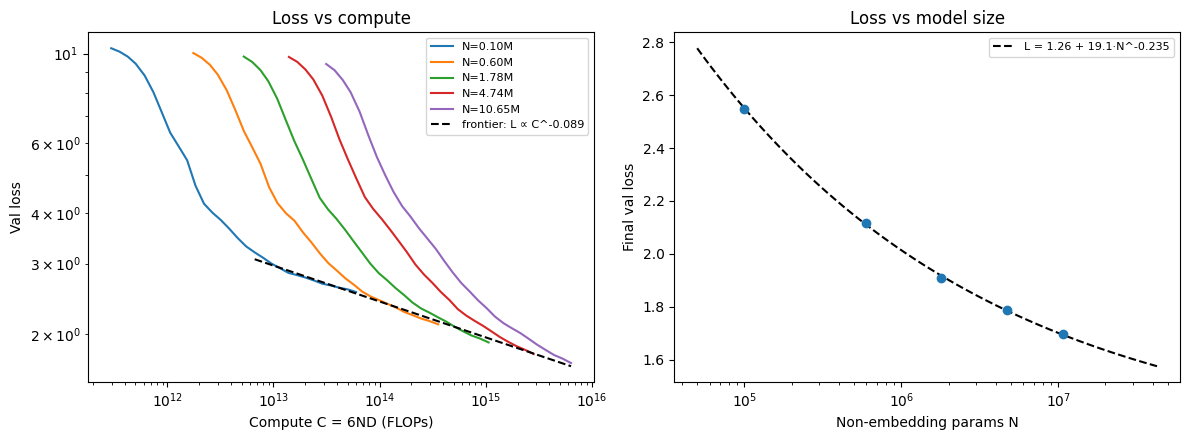

alpha = 0.235, irreducible E = 1.264, frontier slope = -0.089


In [18]:
# Cell 5: fit + plot
import glob, json, numpy as np, matplotlib.pyplot as plt
from scipy.optimize import curve_fit

runs = sorted((json.load(open(p)) for p in glob.glob(f'{ROOT}/results/*.json')), key=lambda r: r['N'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: loss vs compute, one curve per model, plus the compute frontier
allC, allL = [], []
for r in runs:
    C = np.array([e['flops'] for e in r['log']]); Lv = np.array([e['val_loss'] for e in r['log']])
    ax[0].plot(C, Lv, label=f"N={r['N'] / 1e6:.2f}M")
    allC += list(C); allL += list(Lv)
allC, allL = np.array(allC), np.array(allL)
o = np.argsort(allC); fC, fL = allC[o], np.minimum.accumulate(allL[o])     # lower envelope
keep = np.r_[True, fL[1:] < fL[:-1]]
fC, fL = fC[keep], fL[keep]
m = fC > fC.max() * 1e-3                                                    # ignore warm-up region
b, a = np.polyfit(np.log(fC[m]), np.log(fL[m]), 1)
ax[0].plot(fC[m], np.exp(a) * fC[m] ** b, 'k--', label=f'frontier: L ∝ C^{b:.3f}')
ax[0].set(xscale='log', yscale='log', xlabel='Compute C = 6ND (FLOPs)', ylabel='Val loss', title='Loss vs compute')
ax[0].legend(fontsize=8)

# Right: final loss vs N, fit L = E + A * N^-alpha
N = np.array([r['N'] for r in runs], float); Lf = np.array([r['log'][-1]['val_loss'] for r in runs])
f = lambda n, E, A, al: E + A * n ** (-al)
(E, A, al), _ = curve_fit(f, N, Lf, p0=[Lf.min() * 0.8, 10, 0.3], bounds=([0, 0, 0], [Lf.min(), 1e6, 2]), maxfev=20000)
ns = np.geomspace(N.min() / 2, N.max() * 4, 100)
ax[1].scatter(N, Lf, zorder=3); ax[1].plot(ns, f(ns, E, A, al), 'k--', label=f'L = {E:.2f} + {A:.1f}·N^-{al:.3f}')
ax[1].set(xscale='log', xlabel='Non-embedding params N', ylabel='Final val loss', title='Loss vs model size')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/scaling.png', dpi=200); plt.show()
print(f'alpha = {al:.3f}, irreducible E = {E:.3f}, frontier slope = {b:.3f}')